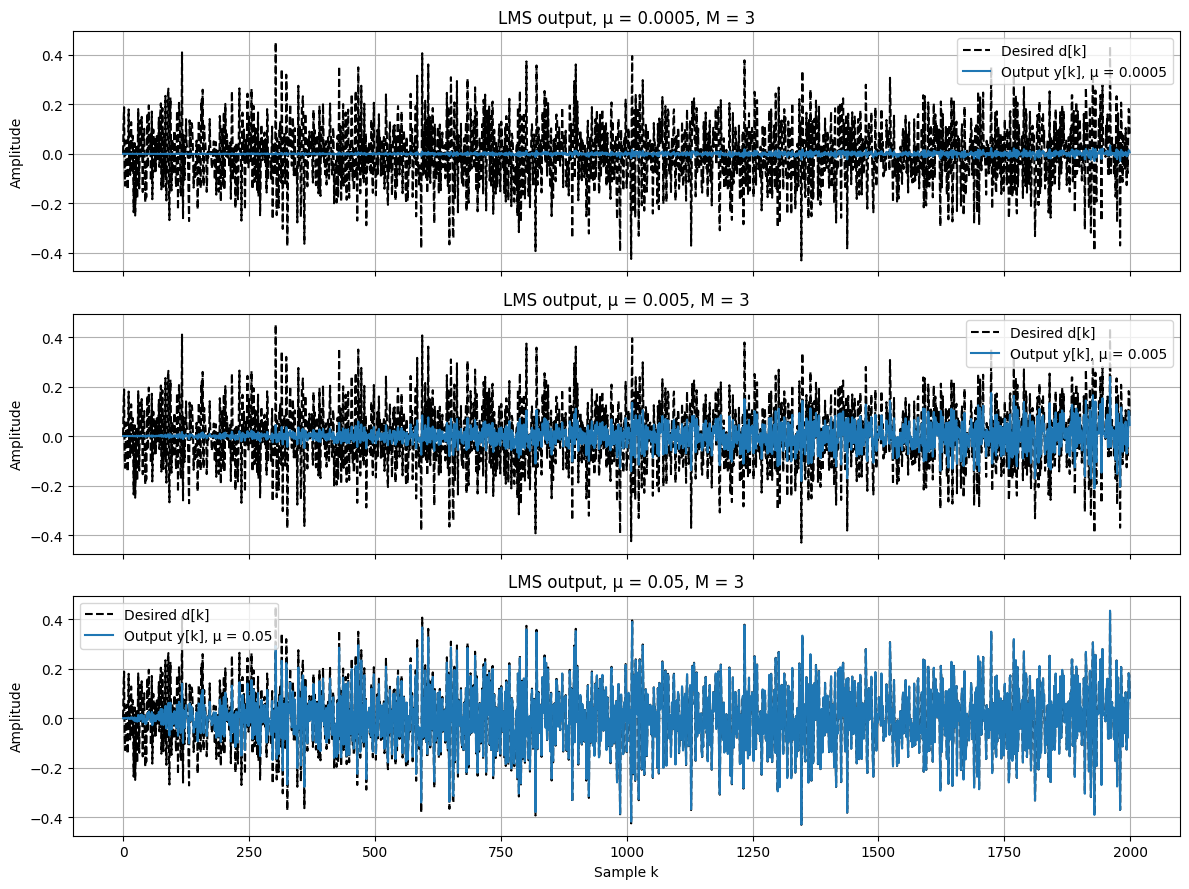

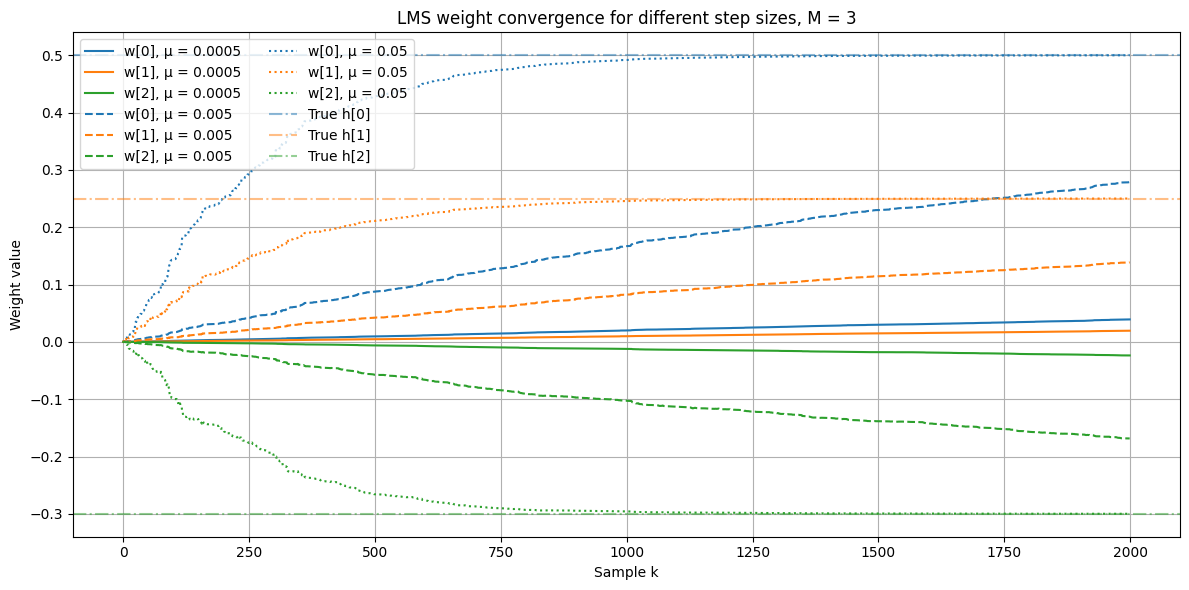

In [40]:
import numpy as np
import matplotlib.pyplot as plt

N = 2000 #samples
M = 3 #taps
mu_values = [0.0005, 0.005, 0.05]

h = np.array([0.5, 0.25, -0.3])

seed = 11
noise_std = 0.2
rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)

use_sinus = False

sin_amp = 1.0
sin_f = 0.05  #normalized frequency (cycles/samples)
if use_sinus:
    x += sin_amp*np.sin(2*np.pi, sin_f * k)


#unknown system

d = np.convolve(x,h,mode="full")[:N]

#container for multiple runs of mu
results = {}

#LMS
for mu in mu_values:
    w = np.zeros(M) #inital weights are zero
    y = np.zeros(N) #adaptive filter output Y
    e = np.zeros(N) #error signal
    w_history = np.zeros((N,M))

    for k in range(M-1, N):
        #
        x_vec = x[k - M + 1:k + 1][::-1] #creates the X[k] vector 
        #extracts M samples from x, including the current samples
        #the reverses the order [::-1]
        
        #adaptive filter output
        y[k] = np.dot(w,x_vec) # W[k]*X[k] to apply the filter

        #calculate error
        e[k] = d[k] - y[k]

        #update the weights
        w = w + 2 * mu * e[k] * x_vec

        #store weights 
        w_history[k] = w

    results[mu] = {
        "y": y.copy(),
        "e": e.copy(),
        "w_history": w_history.copy()
    }


# Plot output signals
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for i, mu in enumerate(mu_values):

    axes[i].plot(d, 'k--', label="Desired d[k]")
    axes[i].plot(results[mu]["y"], label=f"Output y[k], μ = {mu}")

    axes[i].set_ylabel("Amplitude")
    axes[i].set_title(f"LMS output, μ = {mu}, M = {M}")
    axes[i].legend()
    axes[i].grid()

axes[-1].set_xlabel("Sample k")

plt.tight_layout()
plt.show()


# Plot weight convergence
fig, ax = plt.subplots(figsize=(12, 6))

linestyles = ['-', '--', ':']
colors = plt.cm.tab10.colors

for i, mu in enumerate(mu_values):

    for m in range(M):

        ax.plot(
            results[mu]["w_history"][:, m],
            color=colors[m % len(colors)],
            linestyle=linestyles[i],
            label=f"w[{m}], μ = {mu}"
        )

# True system coefficients
for m in range(M):
    ax.axhline(
        h[m],
        color=colors[m % len(colors)],
        linestyle='-.',
        alpha=0.5,
        label=f"True h[{m}]"
    )

ax.set_xlabel("Sample k")
ax.set_ylabel("Weight value")
ax.set_title(f"LMS weight convergence for different step sizes, M = {M}")
ax.legend(loc="best", ncol=2)
ax.grid()

plt.tight_layout()
plt.show()


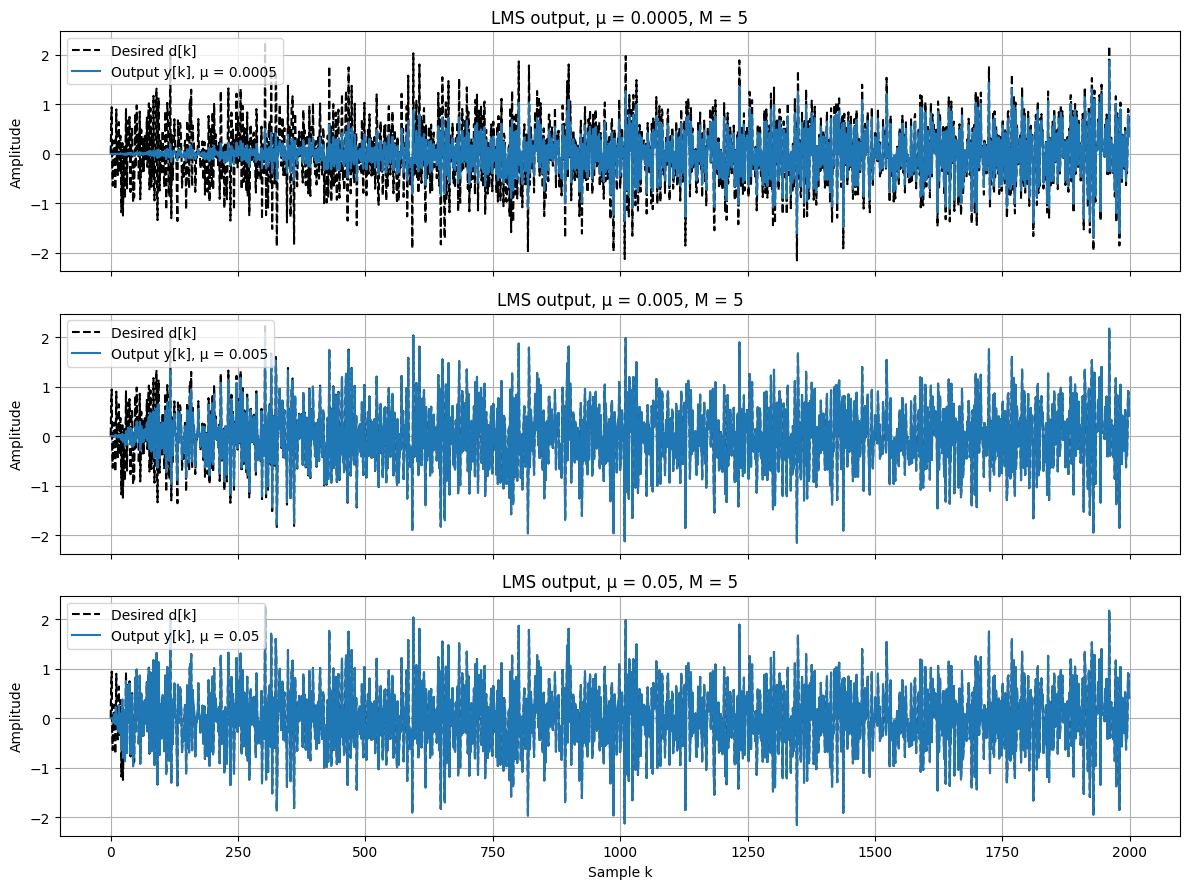

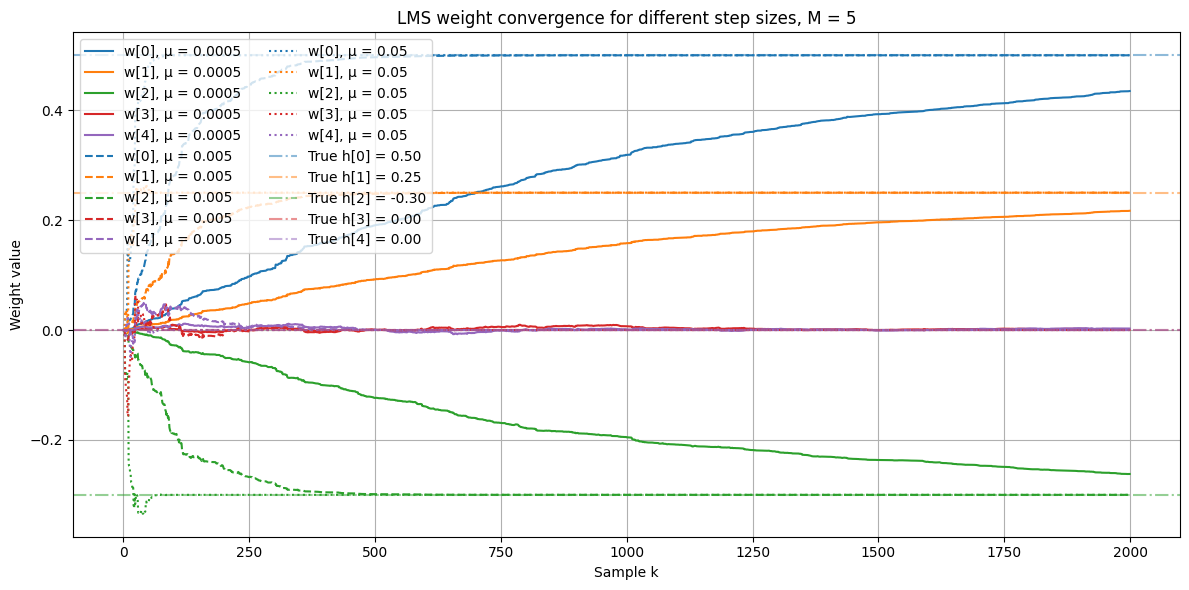

In [30]:
import numpy as np
import matplotlib.pyplot as plt

N = 2000 #samples
M = 5 #taps
mu_values = [0.0005, 0.005, 0.05]

h = np.array([0.5, 0.25, -0.3])

seed = 11
noise_std = 1.0
rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)

use_sinus = False
sin_amp = 1.0
sin_f = 0.05  #normalized frequency (cycles/samples)
if use_sinus:
    x += sin_amp*np.sin(2*np.pi, sin_f * k)


#unknown system

d = np.convolve(x,h,mode="full")[:N]

#container for multiple runs of mu
results = {}

#LMS
for mu in mu_values:
    w = np.zeros(M) #inital weights are zero
    y = np.zeros(N) #adaptive filter output Y
    e = np.zeros(N) #error signal
    w_history = np.zeros((N,M))

    for k in range(M-1, N):
        #
        x_vec = x[k - M + 1:k + 1][::-1] #creates the X[k] vector 
        #extracts M samples from x, including the current samples
        #the reverses the order [::-1]
        
        #adaptive filter output
        y[k] = np.dot(w,x_vec) # W[k]*X[k] to apply the filter

        #calculate error
        e[k] = d[k] - y[k]

        #update the weights
        w = w + 2 * mu * e[k] * x_vec

        #store weights 
        w_history[k] = w

    results[mu] = {
        "y": y.copy(),
        "e": e.copy(),
        "w_history": w_history.copy()
    }


# Plot output signals
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for i, mu in enumerate(mu_values):

    axes[i].plot(d, 'k--', label="Desired d[k]")
    axes[i].plot(results[mu]["y"], label=f"Output y[k], μ = {mu}")

    axes[i].set_ylabel("Amplitude")
    axes[i].set_title(f"LMS output, μ = {mu}, M = {M}")
    axes[i].legend()
    axes[i].grid()

axes[-1].set_xlabel("Sample k")

plt.tight_layout()
plt.show()


# Plot weight convergence
fig, ax = plt.subplots(figsize=(12, 6))

linestyles = ['-', '--', ':']
colors = plt.cm.tab10.colors

for i, mu in enumerate(mu_values):

    for m in range(M):

        ax.plot(
            results[mu]["w_history"][:, m],
            color=colors[m % len(colors)],
            linestyle=linestyles[i],
            label=f"w[{m}], μ = {mu}"
        )

# True system coefficients
# for m in range(M):
#     ax.axhline(
#         h[m],
#         color=colors[m % len(colors)],
#         linestyle='-.',
#         alpha=0.5,
#         label=f"True h[{m}]"
#     )

h_ref = np.zeros(M)
h_ref[:min(M, len(h))] = h[:min(M, len(h))]

for m in range(M):
    ax.axhline(
        h_ref[m],
        color=colors[m % len(colors)],
        linestyle='-.',
        alpha=0.5,
        label=f"True h[{m}] = {h_ref[m]:.2f}"
    )

ax.set_xlabel("Sample k")
ax.set_ylabel("Weight value")
ax.set_title(f"LMS weight convergence for different step sizes, M = {M}")
ax.legend(loc="best", ncol=2)
ax.grid()

plt.tight_layout()
plt.show()


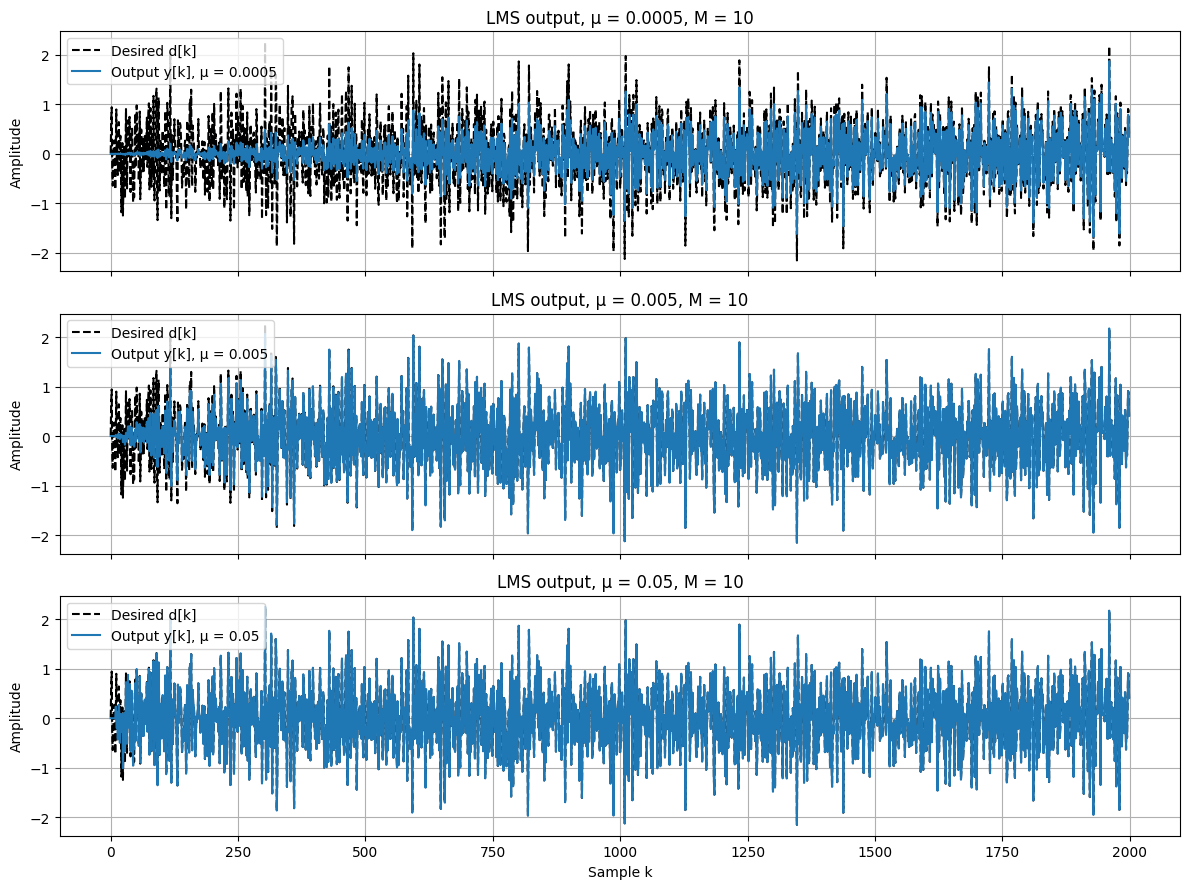

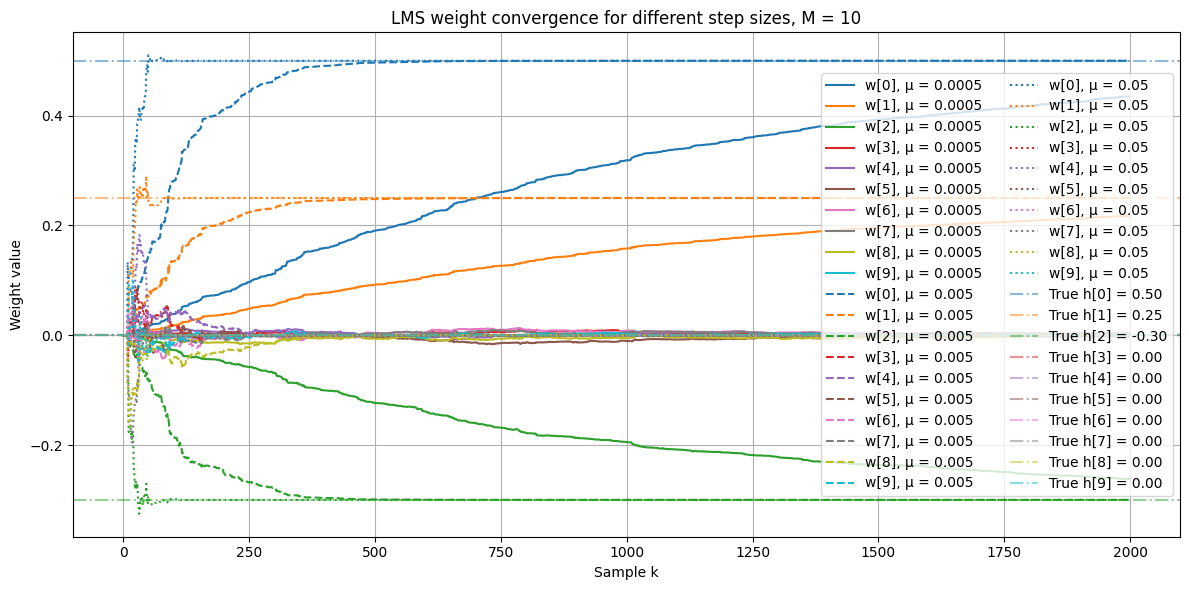

In [32]:
import numpy as np
import matplotlib.pyplot as plt

N = 2000 #samples
M = 10 #taps
mu_values = [0.0005, 0.005, 0.05]

h = np.array([0.5, 0.25, -0.3])

seed = 11
noise_std = 1.0
rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)

use_sinus = False
sin_amp = 1.0
sin_f = 0.05  #normalized frequency (cycles/samples)
if use_sinus:
    x += sin_amp*np.sin(2*np.pi, sin_f * k)


#unknown system

d = np.convolve(x,h,mode="full")[:N]

#container for multiple runs of mu
results = {}

#LMS
for mu in mu_values:
    w = np.zeros(M) #inital weights are zero
    y = np.zeros(N) #adaptive filter output Y
    e = np.zeros(N) #error signal
    w_history = np.zeros((N,M))

    for k in range(M-1, N):
        #
        x_vec = x[k - M + 1:k + 1][::-1] #creates the X[k] vector 
        #extracts M samples from x, including the current samples
        #the reverses the order [::-1]
        
        #adaptive filter output
        y[k] = np.dot(w,x_vec) # W[k]*X[k] to apply the filter

        #calculate error
        e[k] = d[k] - y[k]

        #update the weights
        w = w + 2 * mu * e[k] * x_vec

        #store weights 
        w_history[k] = w

    results[mu] = {
        "y": y.copy(),
        "e": e.copy(),
        "w_history": w_history.copy()
    }


# Plot output signals
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for i, mu in enumerate(mu_values):

    axes[i].plot(d, 'k--', label="Desired d[k]")
    axes[i].plot(results[mu]["y"], label=f"Output y[k], μ = {mu}")

    axes[i].set_ylabel("Amplitude")
    axes[i].set_title(f"LMS output, μ = {mu}, M = {M}")
    axes[i].legend()
    axes[i].grid()

axes[-1].set_xlabel("Sample k")

plt.tight_layout()
plt.show()


# Plot weight convergence
fig, ax = plt.subplots(figsize=(12, 6))

linestyles = ['-', '--', ':']
colors = plt.cm.tab10.colors

for i, mu in enumerate(mu_values):

    for m in range(M):

        ax.plot(
            results[mu]["w_history"][:, m],
            color=colors[m % len(colors)],
            linestyle=linestyles[i],
            label=f"w[{m}], μ = {mu}"
        )

# True system coefficients
# for m in range(M):
#     ax.axhline(
#         h[m],
#         color=colors[m % len(colors)],
#         linestyle='-.',
#         alpha=0.5,
#         label=f"True h[{m}]"
#     )

h_ref = np.zeros(M)
h_ref[:min(M, len(h))] = h[:min(M, len(h))]

for m in range(M):
    ax.axhline(
        h_ref[m],
        color=colors[m % len(colors)],
        linestyle='-.',
        alpha=0.5,
        label=f"True h[{m}] = {h_ref[m]:.2f}"
    )


ax.set_xlabel("Sample k")
ax.set_ylabel("Weight value")
ax.set_title(f"LMS weight convergence for different step sizes, M = {M}")
ax.legend(loc="best", ncol=2)
ax.grid()

plt.tight_layout()
plt.show()
